# 제9교시. Prefill·Decode와 KV 캐시의 실행 비용


## 이번 교시의 목표

- 같은 후속 토큰 경로에서 KV 캐시 재사용과 전체 재계산의 입력 차이를 설명합니다.
- 저장된 반복 시간·중앙값·캐시 바이트를 읽고 측정 구간과 비용의 범위를 구분합니다.
- logits 대조 검사와 속도 관찰을 구분하여 결과를 기록합니다.


## 이번 교시 핵심 용어

- **프리필(prefill)**: 프롬프트 전체를 처음 처리하는 단계입니다.
- **디코드(decode)**: 이후 토큰을 순차 처리하는 단계입니다.
- **첫 토큰까지의 시간(time to first token, TTFT)**: 요청 이후 첫 토큰까지의 시간이며 prefill 연산만의 시간과 다릅니다.
- **중앙값(median)**: 측정값을 순서대로 놓았을 때 가운데에 있는 값입니다.


- **키·값 캐시(key-value cache, KV cache)**: 이전 토큰의 키와 값을 저장해 다음 단계에서 재사용합니다.


## 실습 준비

1교시에서 준비한 Windows 프로젝트의 Python 커널을 선택하고 CUDA 환경을 확인합니다. 앞 교시의 모델이 남아 있으면 해당 커널을 종료하고 새 커널에서 시작합니다. 아래 환경 검사와 실제 출력에서 버전·장치를 확인한 뒤 순서대로 실행합니다.

가중치는 지정된 공식 체크포인트와 revision을 사용합니다. 결과 파일은 이 노트북의 `OUT`에 지정된 폴더에 저장하며, 이미지 실습은 코드로 만든 공개 도형만 사용합니다.

**커널·필수 도구:** 1교시에서 만든 프로젝트의 Python 3.12 커널을 선택합니다. 수업 환경은 PyTorch 2.9.1(CUDA 12.6 빌드), Transformers 5.23.0이며 Pillow·NumPy·Matplotlib·huggingface_hub를 사용합니다. 패키지가 없거나 버전이 다르면 이 노트북에서 임의로 업그레이드하지 말고 1교시에서 준비한 환경을 복구한 뒤 커널을 재시작합니다.

**파일·다운로드:** 실행 셀에서 [GPT-2](https://huggingface.co/openai-community/gpt2/tree/607a30d783dfa663caf39e06633721c8d4cfcd7e)와 [SmolLM2-135M](https://huggingface.co/HuggingFaceTB/SmolLM2-135M/tree/93efa2f097d58c2a74874c7e644dbc9b0cee75a2)의 고정 revision을 읽습니다. 첫 실행에는 공식 모델 저장소 접속과 가중치 다운로드가 필요하며 이후 같은 다운로드 캐시를 재사용합니다. API 키·유료 추론 API·개인 데이터는 필요하지 않습니다. 연결 오류가 나면 실패 셀을 확인하고 네트워크 복구 뒤 그 셀부터 다시 실행합니다. 인증 토큰을 노트북에 적지 않습니다.

**실행·확인 순서:** 위에서부터 개념과 그림, 코드 설명을 본 뒤 코드 셀을 한 번씩 실행하고 바로 아래 실제 출력·출력 설명을 확인합니다. `assert` 오류가 나오면 뒤 셀로 넘어가지 않습니다. CUDA 사용 불가면 장치·커널을 먼저 확인하고, 메모리 부족이면 결과를 보관한 뒤 이전 모델이 남은 커널을 종료하고 새 커널에서 다시 시작합니다. 이미지나 텍스트의 오답은 환경 오류와 구분합니다.

**결과 보관:** `OUT`과 마지막 저장 경로 출력에서 JSON·그림 폴더를 확인합니다. 실행 횟수와 출력이 남은 `.ipynb`도 저장합니다. 다시 실행해 기록이 중복되면 새 커널에서 처음부터 진행합니다.

**오늘의 질문:** 캐시를 켜면 어떤 계산을 다시 쓰고, 어디에서 시간이 드나요?

5교시와 같은 실제 GPT-2·SmolLM2 가중치를 그대로 사용합니다. 한 모델 안에서 **같은 토큰 경로**를 캐시 사용/전체 재계산으로 비교합니다. 이 수업은 서버 벤치마크나 모델 순위표가 아닙니다.


1교시 `.venv` 커널을 선택하고 다른 모델이 남아 있으면 Notebook 커널을 다시 시작합니다. 같은 캐시를 재사용합니다. GPT-2 약548MB·SmolLM2 약269MB 가중치가 없을 때만 공식 파일 다운로드가 필요합니다. 새 패키지는 설치하지 않습니다.


## 1. 비교 조건과 측정 도구
- 두 모델 모두 FP32·eager attention·batch1·동일 GPU0입니다. 모델을 한 번에 하나만 올립니다.
- 각 모델의 토크나이저로 만든 64/256개 입력 토큰을 사용합니다. 동일 토큰 수라도 모델 간 토큰 문자열·어휘는 다르므로 모델 간 속도 우열로 일반화하지 않습니다.
- **Prefill 측정**은 전체 입력의 forward입니다. 토큰화·샘플링·첫 글자 표시가 빠져 있어 서비스 TTFT가 아닙니다.
- **Decode 측정**은 미리 고정한 후속 토큰8개를 차례로 처리하는 forward 구간입니다. 총시간/8은 평균 처리 비용이며 사용자 스트리밍 ITL이 아닙니다.
- 양쪽을 번갈아 측정하고 2회 워밍업 뒤 5회를 기록합니다. 각 측정 앞뒤에 CUDA synchronize를 호출합니다. 상대속도 보장·성능 임계값은 없습니다.

KV 캐시를 이해할 때는 “읽은 문장을 기억한다”보다 **이전 위치의 K·V 계산 결과를 저장한다**고 생각하면 정확합니다. 예를 들어 설명용 토큰 A·B·C 뒤에 D를 처리할 때, 캐시 경로는 D의 표현을 계산하며 저장된 A·B·C의 K·V를 참고합니다. 캐시가 없는 경로는 A·B·C·D를 다시 입력합니다. 두 경로 모두 문맥을 참고하지만 과거 표현을 다시 만드는 작업량이 다릅니다. 자세한 재사용 원리는 [Transformers의 KV 캐시 문서](https://huggingface.co/docs/transformers/cache_explanation)에서 확인할 수 있습니다.

저장 공간과 계산량을 맞바꾸는 선택입니다. K·V를 보관할 메모리가 필요하고, 토큰이 늘면 캐시도 길어집니다. 또 입력이 짧거나 다른 실행 비용이 크면 캐시를 썼다고 항상 더 빨라지지는 않습니다. 그래서 같은 후속 토큰을 두 경로에 넣고 **점수의 일치와 실측 시간**을 따로 확인합니다.

### 개념 먼저

KV 캐시가 필요한 이유를 토큰 세 개짜리 입력으로 생각해 보겠습니다. `가·나·다`를 처리한 뒤 `라`가 추가되면 새 위치는 앞선 세 위치를 참고해야 합니다. 캐시가 없으면 네 위치를 다시 모델에 넣습니다. 캐시가 있으면 앞서 만든 K와 V를 보관하고 새 위치의 계산에 재사용합니다. 이전 위치의 K/V를 다시 만드는 일은 줄지만, 새 Q가 과거 K/V를 읽는 어텐션 계산까지 사라지는 것은 아닙니다.

또한 ‘더 적게 계산한다’와 ‘항상 더 짧게 걸린다’는 같은 말이 아닙니다. 캐시를 보관·조회하는 비용과 GPU 작업을 시작하는 비용도 있기 때문입니다. 이 실습은 후속 토큰 경로를 미리 고정해 계산할 내용은 같게 만들고, 캐시 재사용 여부만 바꿉니다. 아래 `tokens`와 `prefixes`가 각각 새 토큰 하나와 전체 접두부를 나타내는 이유입니다.


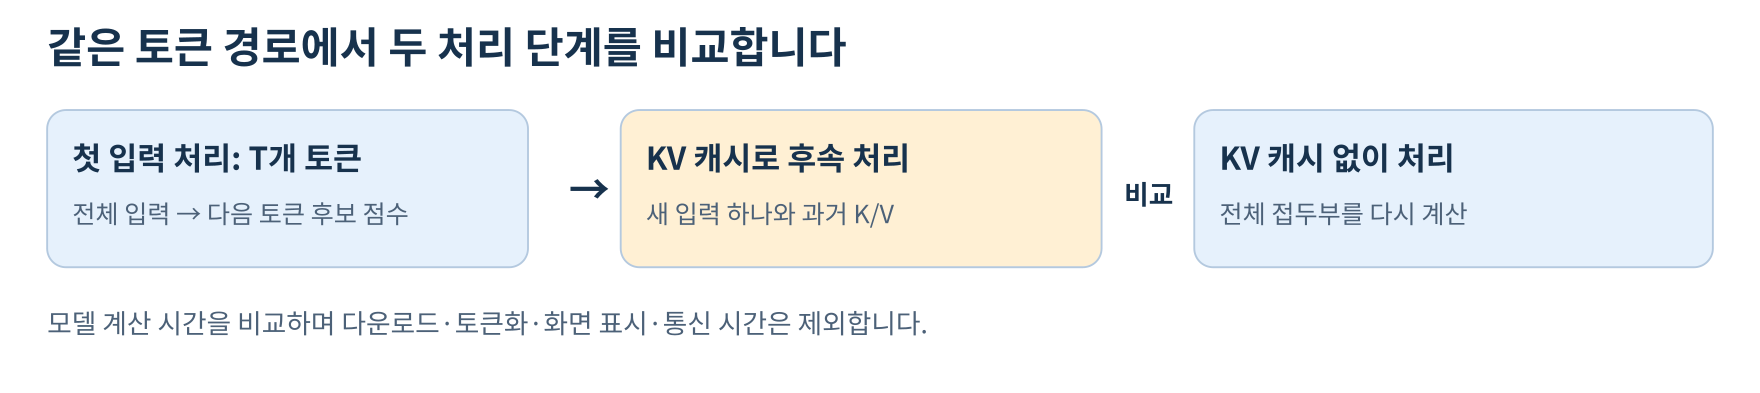

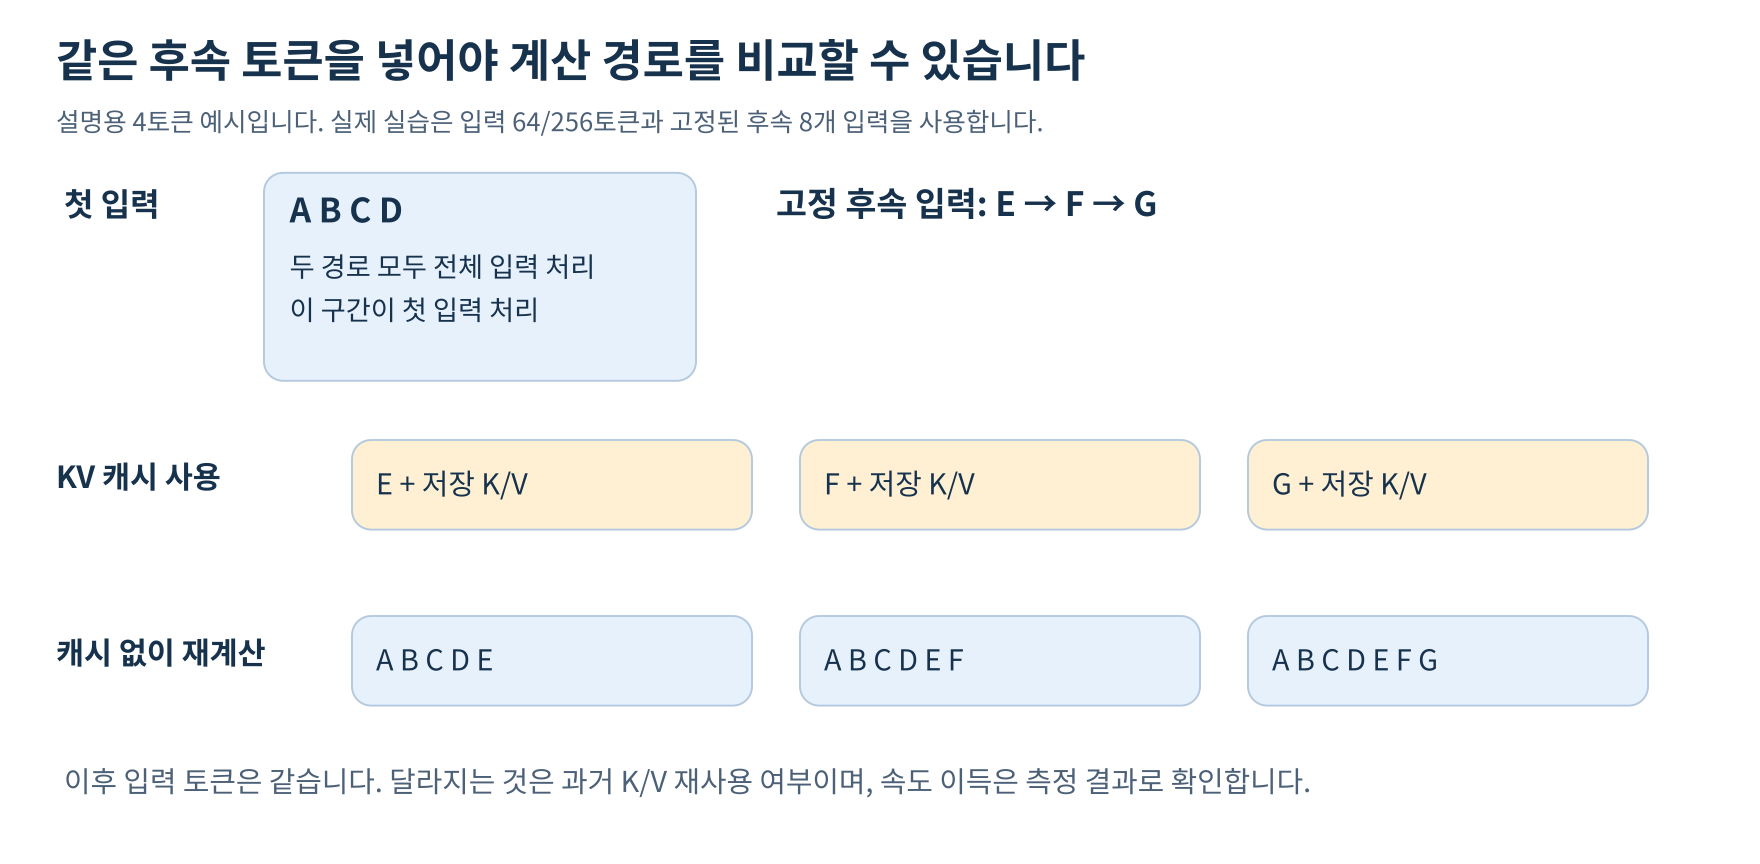

**그림 설명:** 설명용 문자 토큰으로 계산 입력의 차이를 보입니다. 실측 시간이나 생성 문장 예측이 아닙니다.


### 코드 설명: 같은 계산을 두 가지 방법으로 실행하기

`prefill`은 프롬프트 전체를 처음 처리하는 단계이고, `decode`는 이후 토큰을 순차적으로 처리하는 단계입니다. KV 캐시는 이전 토큰의 Key와 Value를 저장하여 재사용합니다. 가중치를 바꾸거나 이전 계산 전체를 저장하는 장치가 아니라, 과거 K/V의 재계산을 줄이는 대신 메모리를 사용하는 선택입니다. 이 셀은 두 모델과 입력 길이 64·256, 반복 횟수, 측정 함수를 준비합니다. `revision`은 모델 파일의 특정 버전을 고정합니다.

`trajectory`로 후속 8토큰을 먼저 정한 뒤 두 방법에 똑같이 넣는 것이 핵심입니다. 캐시 사용 경로는 매번 1토큰을, 재계산 경로는 그때까지의 전체 토큰열을 입력합니다. `torch.allclose`는 마지막 위치의 logits가 허용 오차 안에서 같은지 검사합니다. 준비 단계의 `[PASS]`는 속도 개선을 증명하지 않습니다. 첫 2회는 워밍업으로 버리고 다음 5회를 기록하며, GPU 동기화는 비동기 연산이 끝나기 전에 시계를 멈추는 오류를 줄입니다. 이 실험은 모델 로딩이나 토큰화까지 포함한 서비스 응답시간 측정이 아닙니다.

**이 비교의 허용 오차:** `torch.allclose(cached[1], full[1], atol=2e-4, rtol=2e-4)`는 캐시 경로의 마지막 logits를 전체 재계산 경로의 마지막 logits와 원소별로 비교합니다. 두 번째 인수 `full[1]`이 기준값입니다. 각 차이가 `0.0002 + 0.0002 × |기준 logits|` 이하여야 하므로, 절대 허용량 0.0002에 기준 크기의 0.02%를 더합니다. 0 부근에서도 작은 차이를 허용하면서 큰 값에는 비례 허용량을 적용하는 방식입니다. 부동소수점 연산 순서 차이를 받아들이기 위한 비교 기준이지 모델 정답률 기준은 아닙니다.

출력의 `max_logits_delta`는 가장 큰 절대 차이를 요약한 진단값입니다. 그 값이 0.0002를 넘더라도 상대 허용량까지 포함하면 검사가 통과할 수 있습니다. 이 요약만으로 최대 차이 위치의 실제 기준 logits나 그 위치의 허용량을 알아낼 수는 없습니다. 모든 원소의 통과 여부는 실제 `allclose` 검사로 확인합니다. [PyTorch의 allclose 설명](https://docs.pytorch.org/docs/stable/generated/torch.allclose.html)에서 이 원소별 판정식을 확인할 수 있습니다.


In [1]:
import os, sys, gc, json, time, platform, statistics
from pathlib import Path
from datetime import datetime, timezone
import torch, transformers
from transformers import AutoModelForCausalLM, AutoTokenizer
import matplotlib.pyplot as plt
assert platform.system() == "Windows", "Windows 11 프로젝트 커널을 사용하세요."
assert torch.cuda.is_available(), "1교시 CUDA 검증을 먼저 확인하세요."
DEVICE = torch.device("cuda:0")
# 첫 실행의 준비 비용을 줄이기 위해 워밍업은 기록에서 제외하고 여러 번 측정합니다.
WARMUP, REPEATS, STEPS = 2, 5, 8
LENGTHS = (64, 256)
SPECS = {
    "GPT-2": dict(repo="openai-community/gpt2", revision="607a30d783dfa663caf39e06633721c8d4cfcd7e", cache_env="LESSON05_GPT2_CACHE"),
    "SmolLM2": dict(repo="HuggingFaceTB/SmolLM2-135M", revision="93efa2f097d58c2a74874c7e644dbc9b0cee75a2", cache_env="LESSON05_SMOL_CACHE"),
}
RUN = {"created_utc":datetime.now(timezone.utc).isoformat(), "pc":platform.node(),
       "platform":platform.platform(), "python":sys.version, "executable":sys.executable,
       "torch":torch.__version__, "transformers":transformers.__version__,
       "gpu":torch.cuda.get_device_name(0), "dtype":"float32", "attention":"eager",
       "batch":1, "warmups":WARMUP, "repeats":REPEATS, "steps":STEPS, "models":SPECS}
OUT = Path("results") / "lesson09" / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
OUT.mkdir(parents=True, exist_ok=False)
print(json.dumps(RUN, ensure_ascii=False, indent=2))

def cache_bytes(cache):
    # 원소 수 × 원소당 바이트를 모든 층의 K/V에 합산합니다.
    return sum(t.numel()*t.element_size() for layer in cache.layers for t in (layer.keys,layer.values))

# name으로 SPECS의 저장소와 고정 revision을 골라 모델·토크나이저·입력 ID를 함께 반환합니다.
def load(name):
    spec=SPECS[name]
    # cache_dir는 다운로드 파일 보관 위치이며 추론 중 K/V 캐시와 다릅니다.
    args=dict(revision=spec["revision"],cache_dir=os.environ.get(spec["cache_env"]) or None)
    tokenizer=AutoTokenizer.from_pretrained(spec["repo"],**args)
    model=AutoModelForCausalLM.from_pretrained(spec["repo"],**args,use_safetensors=True,
        dtype=torch.float32,attn_implementation="eager").to(DEVICE).eval()
    assert all(p.device.type=="cuda" for p in model.parameters())
    text=("The students compare memory and computation in a language model. " * 120)
    ids=tokenizer(text,return_tensors="pt",add_special_tokens=False).input_ids.to(DEVICE)
    assert ids.shape[1]>=max(LENGTHS)
    print(name, "loaded real checkpoint", spec["revision"])
    return model,tokenizer,ids

@torch.inference_mode()
def timed_forward(fn):
    torch.cuda.synchronize(DEVICE)
    # 동기화 뒤 시간을 재고, 함수 반환 전에도 GPU 완료를 기다립니다.
    start=time.perf_counter()
    out=fn()
    torch.cuda.synchronize(DEVICE)
    return (time.perf_counter()-start)*1000, out

@torch.inference_mode()
def compare_length(model, ids, T):
    # T개 토큰을 잘라 (1,T) 입력을 만듭니다. contiguous는 내용이 아니라 메모리 배치를 맞춥니다.
    prompt=ids[:,:T].contiguous()
    mask=torch.ones_like(prompt)
    # 실제 모델의 greedy 후속 토큰을 먼저 정합니다. 이 생성은 측정 밖입니다.
    trajectory=model.generate(input_ids=prompt,attention_mask=mask,max_new_tokens=STEPS,
        min_new_tokens=STEPS,do_sample=False,use_cache=True,
        pad_token_id=model.config.eos_token_id)
    assert trajectory.shape[1]==T+STEPS
    # 한 토큰 입력 (1,1)과 전체 접두부 (1,T+i+1)에 같은 후속 토큰을 사용합니다.
    tokens=[trajectory[:,T+i:T+i+1] for i in range(STEPS)]
    prefixes=[trajectory[:,:T+i+1] for i in range(STEPS)]
    masks=[torch.ones_like(x) for x in prefixes]
    def one_prefill(): return model(input_ids=prompt,attention_mask=mask,use_cache=True)
    def cached_decode():
        # Decode 비용에서 prefill을 제외하며 매 반복마다 새 캐시로 시작합니다.
        initial=one_prefill()
        # 첫 입력에서 만든 층별 K/V를 후속 입력에 넘길 상태로 보관합니다.
        past=initial.past_key_values
        before=cache_bytes(past)
        del initial
        def work():
            # 중첩 함수 밖의 캐시 변수를 갱신하여 다음 토큰도 누적된 문맥을 사용하게 합니다.
            nonlocal past
            for token,full_mask in zip(tokens,masks):
                # token은 (1,1)이지만 full_mask는 과거를 포함한 전체 길이를 가리킵니다.
                out=model(input_ids=token,attention_mask=full_mask,past_key_values=past,use_cache=True)
                past=out.past_key_values
            return out
        elapsed,out=timed_forward(work)
        # 시간, 마지막 logits 등을 반환하며 logits는 다음 위치의 후보 점수입니다.
        return elapsed,out.logits[:,-1].detach().clone(),before,cache_bytes(out.past_key_values),out.past_key_values.get_seq_length()
    def full_decode():
        def work():
            for full_ids,full_mask in zip(prefixes,masks):
                # 같은 경로의 전체 접두부를 다시 넣고 캐시 반환을 꺼 재계산 조건을 만듭니다.
                out=model(input_ids=full_ids,attention_mask=full_mask,use_cache=False)
            return out
        elapsed,out=timed_forward(work)
        return elapsed,out.logits[:,-1].detach().clone()
    values={"prefill_ms":[],"cached_decode8_ms":[],"recompute_decode8_ms":[]}
    max_delta=0.0
    for rep in range(WARMUP+REPEATS):
        pre_ms,pre=timed_forward(one_prefill)
        del pre
        # 실행 순서의 편향을 줄이되 정밀 벤치마크로 간주하지 않습니다.
        if rep%2==0: cached=cached_decode(); full=full_decode()
        else: full=full_decode(); cached=cached_decode()
        delta=(cached[1]-full[1]).abs().max().item()
        max_delta=max(max_delta,delta)
        # 절대·상대 허용 오차를 함께 적용하여 두 계산 경로의 수치를 비교합니다.
        # 각 logits 원소에서 |cached−full| ≤ 0.0002+0.0002×|full|이면 통과합니다.
        assert torch.allclose(cached[1],full[1],atol=2e-4,rtol=2e-4), f"동일 경로 logits 차이: {delta}"
        assert cached[4]==T+STEPS and cached[3]>cached[2]
        # 준비 반복 2회는 버리고 조건별 시간 표본 5개를 남깁니다.
        if rep>=WARMUP:
            values["prefill_ms"].append(pre_ms)
            values["cached_decode8_ms"].append(cached[0])
            values["recompute_decode8_ms"].append(full[0])
    return {"prompt_tokens":T,"replayed_tokens":STEPS,"trajectory_ids":trajectory[0].tolist(),
            "cache_before_bytes":cached[2],"cache_after_bytes":cached[3],"max_logits_delta":max_delta,
            "samples":values,"median_ms":{k:statistics.median(v) for k,v in values.items()}}

records=[]
print("[PASS] 측정 조건·도구 준비. 아래 각 모델을 한 번씩 실행하세요.")

%USERPROFILE%\AI-Engineering\python31210-signed-qa-20261117\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "created_utc": "2026-11-17T13:10:10.298934+00:00",
  "pc": "검증 PC",
  "platform": "Windows-11-10.0.26300-SP0",
  "python": "3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]",
  "executable": "%USERPROFILE%\\AI-Engineering\\python31210-signed-qa-20261117\\.venv\\Scripts\\python.exe",
  "torch": "2.9.1+cu126",
  "transformers": "5.23.0",
  "gpu": "NVIDIA GeForce RTX 4090",
  "dtype": "float32",
  "attention": "eager",
  "batch": 1,
  "warmups": 2,
  "repeats": 5,
  "steps": 8,
  "models": {
    "GPT-2": {
      "repo": "openai-community/gpt2",
      "revision": "607a30d783dfa663caf39e06633721c8d4cfcd7e",
      "cache_env": "LESSON05_GPT2_CACHE"
    },
    "SmolLM2": {
      "repo": "HuggingFaceTB/SmolLM2-135M",
      "revision": "93efa2f097d58c2a74874c7e644dbc9b0cee75a2",
      "cache_env": "LESSON05_SMOL_CACHE"
    }
  }
}
[PASS] 측정 조건·도구 준비. 아래 각 모델을 한 번씩 실행하세요.


### 출력 설명

저장된 출력은 Python 3.12.10·PyTorch 2.9.1+cu126·Transformers 5.23.0, RTX 4090에서 실행한 기록입니다. 이 장치에서 통과한 기록을 다른 GPU의 속도나 메모리 충분함에 대한 보장으로 읽지 않습니다. 

실행 설정은 FP32·eager attention·배치 1이며 워밍업 2회 뒤 표본 5개, 후속 입력 8개를 비교하도록 준비됐습니다. 마지막 PASS는 조건과 함수를 준비했다는 뜻이고 실제 시간 비교는 아직 수행하지 않았습니다.

IProgress 경고는 진행 막대용 위젯을 찾지 못했다는 안내입니다. 이 기록은 이후 PASS까지 진행했으므로 가중치나 CUDA 계산 실패의 증거가 아닙니다.

이후 logits 비교 PASS는 각 원소에 `|cached−full| ≤ 0.0002 + 0.0002×|full|`를 적용한 결과입니다. 여기서 `full`은 전체 재계산 경로의 기준 logits입니다. 이 준비 셀의 PASS 자체는 아직 모델별 비교를 수행했다는 뜻이 아닙니다.


## 2. GPT-2 측정
먼저 64토큰과 256토큰에서 어떤 구간의 비용이 달라질지 예상하세요. 출력의 모든 시간은 **지금 표시된 PC·GPU·라이브러리·조건**에서만 측정된 값입니다. 짧은 입력에서는 캐시 관리 비용 때문에 결과가 예상과 다를 수도 있습니다. 속도 순위나 정해진 가속비를 요구하지 않습니다.

### 코드 설명: GPT-2의 캐시 비용과 이득

실제 GPT-2 가중치를 불러와 입력 길이별로 동일한 실험을 수행합니다. `prefill_ms`는 첫 입력 처리 시간, `cached_decode8_ms`는 준비된 캐시로 8개 입력을 차례로 처리한 시간, `recompute_decode8_ms`는 전체 문맥을 매번 다시 계산한 시간입니다. 캐시 경로의 prefill은 decode 측정 구간 밖에 있으므로 두 시간을 무심코 합치거나 서로 같은 작업으로 비교하지 마세요.

출력 JSON의 `max_logits_delta`와 `[PASS] ... logits 대조 완료`는 계산 결과의 일치 검사를, `cache_before_bytes`와 `cache_after_bytes`는 토큰 추가에 따른 K/V 저장량 증가를 보여 줍니다. 이 바이트 수는 K/V 텐서 자체만의 크기이며 모델 가중치나 전체 GPU 사용량이 아닙니다. 발췌 출력에는 모든 JSON 항목이 보이지 않을 수 있으므로 상세 수치는 `measurements.json`에서도 확인하세요. `finally`는 오류가 발생하더라도 모델 참조를 정리하려는 장치입니다.


In [2]:
# 두 방법에 같은 토큰 경로를 넣어 계산 결과와 처리 비용을 비교합니다.
model,tokenizer,ids=load("GPT-2")
try:
    # 입력 길이 64와 256을 각각 측정합니다. 한 조건 안의 준비 반복·5개 표본 수집은 함수가 담당합니다.
    for T in LENGTHS:
        result=compare_length(model,ids,T)
        result["model"]="GPT-2"
        # 조건별 결과를 누적하므로 아래 JSON에는 앞서 끝난 조건도 포함됩니다.
        records.append(result)
        # 화면에서만 긴 trajectory_ids를 생략하며 저장 파일에는 그대로 남깁니다.
        print(json.dumps({k:v for k,v in result.items() if k!="trajectory_ids"},indent=2))
        # 완료된 조건마다 파일을 갱신하므로 뒤 조건이 중단되어도 앞 기록은 남습니다.
        (OUT/"measurements.json").write_text(json.dumps({"run":RUN,"records":records},ensure_ascii=False,indent=2),encoding="utf-8")
# 중간 오류가 나도 모델 참조를 정리하지만 마지막 PASS까지 실행되는 것은 아닙니다.
finally:
    del model,tokenizer,ids
    gc.collect(); torch.cuda.empty_cache()
print("[PASS] GPT-2: 실제 동일 토큰 경로·캐시 증가·logits 대조 완료")

W1117 22:10:11.328000 30312 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.



Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


Loading weights:   3%|▎         | 5/148 [00:00<00:04, 29.36it/s]


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 853.98it/s]


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1321 > 1024). Running this sequence through the model will result in indexing errors


GPT-2 loaded real checkpoint 607a30d783dfa663caf39e06633721c8d4cfcd7e


{
  "prompt_tokens": 64,
  "replayed_tokens": 8,
  "cache_before_bytes": 4718592,
  "cache_after_bytes": 5308416,
  "max_logits_delta": 0.000274658203125,
  "samples": {
    "prefill_ms": [
      6.102499999542488,
      6.120800000644522,
      7.550400001491653,
      9.658099999796832,
      6.551700000272831
    ],
    "cached_decode8_ms": [
      54.38449999928707,
      51.61399999997229,
      44.96559999824967,
      43.87689999930444,
      61.4093000003777
    ],
    "recompute_decode8_ms": [
      43.2476999994833,
      43.99659999762662,
      43.2838000015181,
      53.04410000098869,
      42.20359999817447
    ]
  },
  "median_ms": {
    "prefill_ms": 6.551700000272831,
    "cached_decode8_ms": 51.61399999997229,
    "recompute_decode8_ms": 43.2838000015181
  },
  "model": "GPT-2"
}


{
  "prompt_tokens": 256,
  "replayed_tokens": 8,
  "cache_before_bytes": 18874368,
  "cache_after_bytes": 19464192,
  "max_logits_delta": 0.00028228759765625,
  "samples": {
    "prefill_ms": [
      9.07309999820427,
      6.3655000012659,
      7.1303000004263595,
      7.0410000007541385,
      6.117100001574727
    ],
    "cached_decode8_ms": [
      46.762599999055965,
      46.32140000103391,
      48.199500000919215,
      50.118400002247654,
      45.63129999951343
    ],
    "recompute_decode8_ms": [
      41.37750000154483,
      41.21669999949518,
      55.61409999791067,
      42.62720000042464,
      42.511700001341524
    ]
  },
  "median_ms": {
    "prefill_ms": 7.0410000007541385,
    "cached_decode8_ms": 46.762599999055965,
    "recompute_decode8_ms": 42.511700001341524
  },
  "model": "GPT-2"
}
[PASS] GPT-2: 실제 동일 토큰 경로·캐시 증가·logits 대조 완료


### 출력 설명

64토큰에서는 캐시 사용 51.61 ms와 재계산 43.28 ms, 256토큰에서는 46.76 ms와 42.51 ms로 이 실행의 두 중앙값 모두 재계산 쪽이 짧았습니다. 이 값은 후속 8개 입력 처리 구간의 중앙값입니다. 캐시의 사전 prefill을 포함한 전체 응답시간이 아니며, 캐시 재사용이 모든 짧은 실험에서 반드시 가속을 만든다는 주장은 이 출력으로 지지되지 않습니다.

256토큰 조건의 K/V 저장량은 18,874,368에서 19,464,192바이트로 늘었습니다. 캐시 길이와 저장 증가를 확인한 동시에 logits 대조 PASS가 나왔습니다. 최대 점수 차이가 절대 허용 오차보다 큰 숫자로 보여도 `allclose`는 상대 허용 오차도 적용하므로 최대 차이 하나만으로 실패를 판정하지 않습니다.

1321>1024 경고는 길게 토큰화해 둔 원문에 대한 것입니다. 실제 forward 입력은 64·256토큰으로 잘랐고 후속 8개를 포함해도 한도 안에 있습니다. 전체 1321토큰을 그대로 모델에 넣어도 안전하다는 뜻은 아닙니다.

프로세스 출력 리다이렉션 미지원 안내가 함께 기록됐지만 모델 로드·검사는 완료됐습니다. 이 메시지를 모델의 추론 실패나 수업에 필요한 분산 실행 설정으로 해석하지 않습니다.


## 3. SmolLM2 측정
먼저 64토큰과 256토큰에서 어떤 구간의 비용이 달라질지 예상하세요. 출력의 모든 시간은 **지금 표시된 PC·GPU·라이브러리·조건**에서만 측정된 값입니다. 짧은 입력에서는 캐시 관리 비용 때문에 결과가 예상과 다를 수도 있습니다. 속도 순위나 정해진 가속비를 요구하지 않습니다.

### 코드 설명: 같은 절차로 SmolLM2 관찰하기

두 번째 모델에도 같은 입력 길이, 반복 횟수, 8토큰 재생 절차를 적용합니다. 공정한 비교의 첫 기준은 각 모델 안에서 캐시 사용 여부만 바꿨을 때의 변화입니다. 두 모델은 토크나이저와 구조가 다르므로 64토큰이 같은 글자 수를 뜻하지 않으며, 모델 간 시간 차이를 단 하나의 구조 차이 때문이라고 단정할 수도 없습니다.

`cache_before_bytes → cache_after_bytes`가 증가하고 `max_logits_delta`가 허용 범위를 만족하는지 확인하세요. KV 캐시의 크기는 층 수, K/V head 수, head 차원, 토큰 수, 자료형에 함께 좌우됩니다. `[PASS] SmolLM2...`는 실제 체크포인트에서 지정한 입력 경로와 검사를 통과했다는 뜻이지, SmolLM2가 GPT-2보다 항상 빠르거나 우수하다는 뜻은 아닙니다.


In [3]:
# 모델을 바꿔도 실험 절차는 유지하되, 모델 간 차이의 원인은 하나로 단정하지 않습니다.
# 토크나이저는 달라지지만 길이·반복·시간 측정 함수는 앞 모델과 공유합니다.
model,tokenizer,ids=load("SmolLM2")
try:
    for T in LENGTHS:
        # 길이 T는 문자 수가 아니라 이 토크나이저의 토큰 수입니다. 같은 T라도 두 모델의 문자열 범위는 다를 수 있습니다.
        result=compare_length(model,ids,T)
        result["model"]="SmolLM2"
        # 같은 셀을 다시 실행하면 중복 기록이 생기므로 처음부터 순서대로 실행합니다.
        records.append(result)
        print(json.dumps({k:v for k,v in result.items() if k!="trajectory_ids"},indent=2))
        # 앞 모델 기록과 이번 모델 기록을 함께 저장하여 조건별 비교가 가능하게 합니다.
        (OUT/"measurements.json").write_text(json.dumps({"run":RUN,"records":records},ensure_ascii=False,indent=2),encoding="utf-8")
finally:
    del model,tokenizer,ids
    gc.collect(); torch.cuda.empty_cache()
print("[PASS] SmolLM2: 실제 동일 토큰 경로·캐시 증가·logits 대조 완료")


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


Loading weights:  56%|█████▌    | 151/272 [00:00<00:00, 1502.11it/s]


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1490.09it/s]

SmolLM2 loaded real checkpoint 93efa2f097d58c2a74874c7e644dbc9b0cee75a2


{
  "prompt_tokens": 64,
  "replayed_tokens": 8,
  "cache_before_bytes": 2949120,
  "cache_after_bytes": 3317760,
  "max_logits_delta": 3.24249267578125e-05,
  "samples": {
    "prefill_ms": [
      22.430199998780154,
      24.416700001893332,
      22.454300000390504,
      21.62089999910677,
      21.210800001426833
    ],
    "cached_decode8_ms": [
      151.35229999941657,
      158.73939999801223,
      166.65649999777088,
      153.9133000005677,
      153.52879999772995
    ],
    "recompute_decode8_ms": [
      153.7075999985973,
      160.23149999818997,
      167.34980000182986,
      163.71640000215848,
      162.54599999956554
    ]
  },
  "median_ms": {
    "prefill_ms": 22.430199998780154,
    "cached_decode8_ms": 153.9133000005677,
    "recompute_decode8_ms": 162.54599999956554
  },
  "model": "SmolLM2"
}


{
  "prompt_tokens": 256,
  "replayed_tokens": 8,
  "cache_before_bytes": 11796480,
  "cache_after_bytes": 12165120,
  "max_logits_delta": 3.62396240234375e-05,
  "samples": {
    "prefill_ms": [
      23.21210000081919,
      21.570199998677708,
      22.619100000156322,
      20.45469999939087,
      32.33339999860618
    ],
    "cached_decode8_ms": [
      161.32830000060494,
      155.9404999970866,
      168.7138999986928,
      171.2492000006023,
      171.38409999824944
    ],
    "recompute_decode8_ms": [
      168.4339000021282,
      162.60329999931855,
      158.81979999903706,
      159.9335000028077,
      179.71500000203378
    ]
  },
  "median_ms": {
    "prefill_ms": 22.619100000156322,
    "cached_decode8_ms": 168.7138999986928,
    "recompute_decode8_ms": 162.60329999931855
  },
  "model": "SmolLM2"
}
[PASS] SmolLM2: 실제 동일 토큰 경로·캐시 증가·logits 대조 완료


### 출력 설명

64토큰은 캐시 사용 153.91 ms와 재계산 162.55 ms로 캐시 쪽이 짧았지만, 256토큰은 168.71 ms와 162.60 ms로 순서가 바뀌었습니다. 저장된 반복 표본에도 변동이 있으므로 작은 중앙값 차이를 모델 구조의 보편적 우열로 일반화하지 않습니다.

256토큰 조건의 K/V는 11,796,480에서 12,165,120바이트로 증가했고 두 길이 조건 모두 logits 대조를 통과했습니다. 이는 메모리를 써서 과거 K/V를 재사용하는 경로가 계산 결과를 유지했다는 확인이며, 전체 GPU 메모리 사용량이나 서비스 처리량 측정은 아닙니다.


## 4. 표와 그림으로 구분하기
왼쪽은 prompt 전체 prefill, 오른쪽은 **8개 후속 입력 처리**의 시간입니다. 서로 다른 구간을 같은 ‘생성시간’으로 섞지 않습니다. 점은 5회 개별 측정이고 막대는 중앙값입니다. 캐시 바이트는 논리적 K+V payload이며 CUDA allocator 예약량/모델 가중치/전체 VRAM 사용량이 아닙니다.

**측정 범위:** 같은 모델과 토큰 경로에서 KV 캐시를 사용한 경로와 전체 재계산 경로를 비교합니다. FlashAttention을 켜고 끈 실험이 아니므로, 이 시간 차이를 FlashAttention의 효과로 해석하지 않습니다. 5교시 참고 상자에서 두 최적화가 줄이는 일을 비교했습니다.

### 개념 먼저

사용자가 기다리는 시간에는 여러 구간이 섞입니다. 질문을 토큰으로 바꾸는 시간, 모델이 첫 입력을 계산하는 시간, 답을 고르는 시간, 후속 토큰을 처리하는 시간, 화면에 보내는 시간은 서로 다릅니다. 식당에서 조리 시간과 주문부터 음식 도착까지의 시간이 다른 것처럼, 여기의 모델 계산 시간을 서비스 전체 응답시간으로 읽으면 안 됩니다.

이 실습은 프리필과 후속 입력 8개의 처리 구간을 별도로 잽니다. 캐시 경로의 프리필은 후속 처리 타이머 밖에서 준비합니다. 그래프 두 패널의 막대를 비교할 때 먼저 ‘어느 구간을 재었는가’를 확인하세요. 아래 코드에서 동기화와 타이머의 위치가 측정 범위를 결정하며, 토큰당 요약값도 실제 각 단계의 개별 소요시간과는 구분합니다.


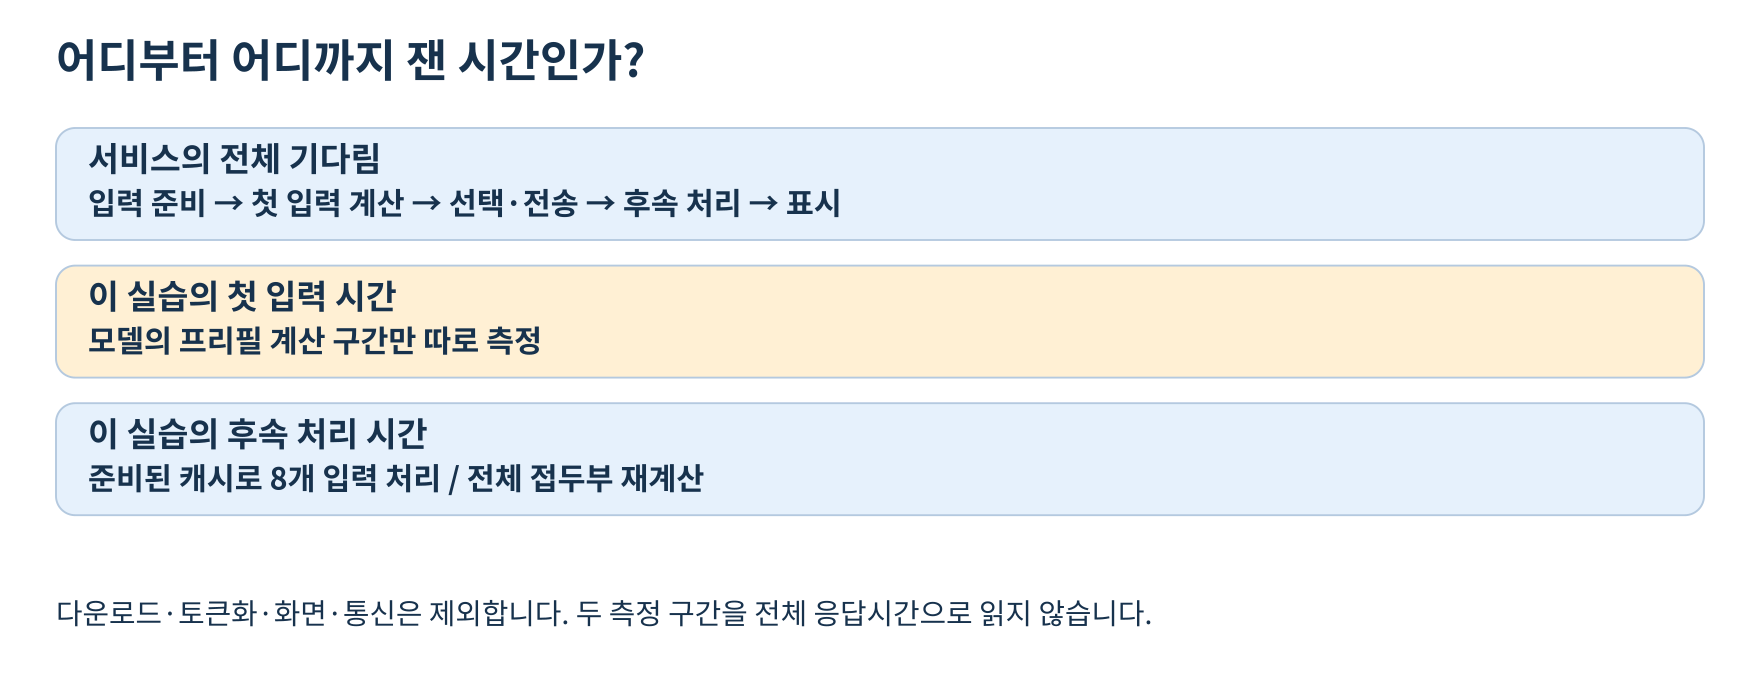

**그림 설명:** 다운로드·토큰화·화면·통신은 제외합니다. 두 측정 구간을 전체 응답시간으로 읽지 않습니다.


### 코드 설명: 시간 그래프와 KV 저장량을 따로 읽기

왼쪽 그래프는 prefill, 오른쪽은 8개 입력 처리의 캐시 사용·재계산 시간을 비교합니다. 막대는 5회 측정의 중앙값이고 검은 점은 개별 측정값입니다. 점이 넓게 흩어지면 단일 시간 수치보다 변동성도 함께 읽어야 합니다. `cached average ms/input`은 8단계 전체 시간의 중앙값을 8로 나눈 값이며, 모든 단계가 실제로 그 시간만큼 걸렸다는 뜻은 아닙니다.

출력의 `K/V payload bytes`와 시간 그래프를 나란히 보면서 “저장 공간을 더 써서 반복 계산을 줄인다”는 교환 관계를 설명해 보세요. 입력 길이 증가의 영향과 모델별 결과는 이 장치·정밀도·구현·batch=1 조건의 관찰입니다. 저장되는 `observed-timings.png`와 `measurements.json`은 측정 조건을 함께 보관하기 위한 자료이며, 이 소규모 실험만으로 일반적인 서비스 성능 순위를 정하지 않습니다.

Windows에 보관된 실제 측정에서는 GPT-2의 T=64에서 캐시 방식 51.614 ms, 재계산 방식 43.284 ms로 오히려 캐시 방식이 더 오래 걸렸습니다. SmolLM2의 T=64에서는 캐시 방식 153.913 ms가 재계산 162.546 ms보다 짧았지만, T=256에서는 반대였습니다. 이는 이 작은 입력·구현·장치 조건에서는 재계산 감소가 곧 실행시간 감소를 보장하지 않는다는 관찰입니다. 구체적인 원인이 캐시 관리 비용인지 호출 비용인지 등은 이 측정만으로 분리하지 못합니다.


GPT-2 64 cached average ms/input: 6.451749999996537 K/V payload bytes: 4718592 → 5308416
GPT-2 256 cached average ms/input: 5.845324999881996 K/V payload bytes: 18874368 → 19464192
SmolLM2 64 cached average ms/input: 19.23916250007096 K/V payload bytes: 2949120 → 3317760
SmolLM2 256 cached average ms/input: 21.0892374998366 K/V payload bytes: 11796480 → 12165120


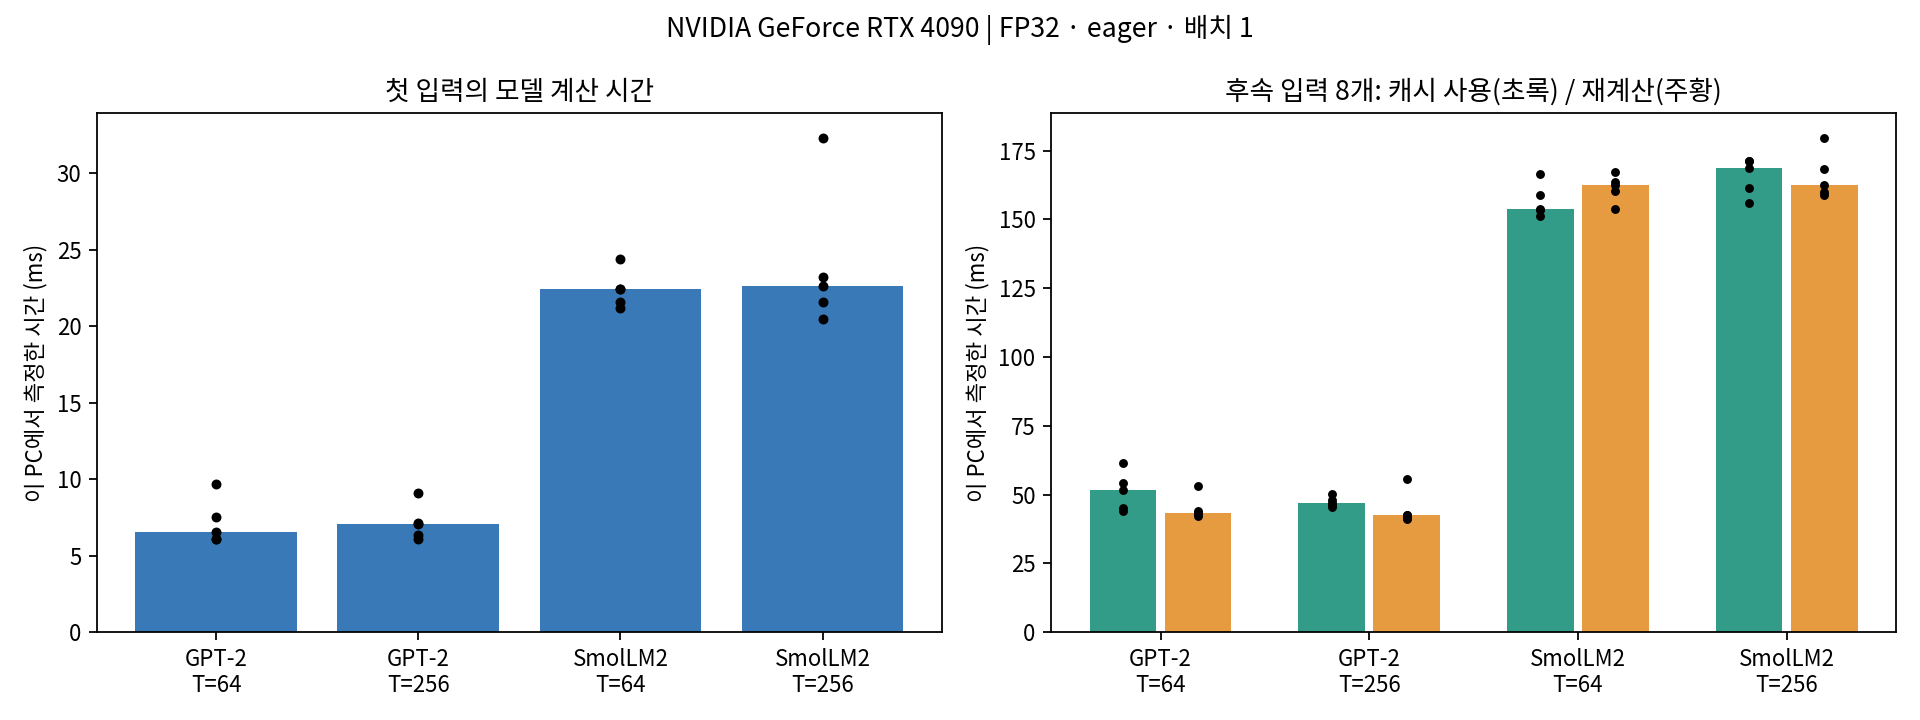

저장: %USERPROFILE%\AI-Engineering\lesson09-qa-20261117\results\lesson09\20261117-221010-300934


In [4]:
from matplotlib import font_manager
# 설치된 한글 글꼴을 등록합니다. 추가 패키지나 다운로드는 사용하지 않습니다.
font_candidates = [Path("C:/Windows/Fonts/malgun.ttf"), Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"), Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")]
for font_path in font_candidates:
    if font_path.is_file():
        font_manager.fontManager.addfont(str(font_path))
        plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(font_path)).get_name()
        break
# for의 else는 break 없이 모든 글꼴 후보를 소진했을 때만 실행됩니다.
else:
    raise RuntimeError("한글 표시용 시스템 글꼴이 없습니다. 저장된 그래프를 참고하거나 한글 글꼴이 있는 환경에서 이 시각화 셀만 다시 실행하세요. 측정 결과는 앞 셀의 JSON에 보관되어 있습니다.")
plt.rcParams["axes.unicode_minus"] = False
# 모델 2개 × 입력 길이 2개의 결과가 모였는지 확인한 뒤 시각화합니다.
assert len(records)==4, "두 모델의 두 입력 길이를 모두 실행하세요."
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
# 가로축은 모델×입력 길이 조건이며 토큰 위치가 아닙니다.
labels=[f"{r['model']}\nT={r['prompt_tokens']}" for r in records]
for i,r in enumerate(records):
    # 막대는 중앙값, 검은 점은 같은 조건의 개별 시간 표본입니다.
    axes[0].bar(i,r["median_ms"]["prefill_ms"],color="#3979b7")
    axes[0].scatter([i]*REPEATS,r["samples"]["prefill_ms"],color="black",s=12)
    # dx는 같은 조건의 두 막대를 좌우로 벌리는 표시 위치이며 측정값을 바꾸지 않습니다.
    for dx,key,color in [(-.18,"cached_decode8_ms","#329c88"),(.18,"recompute_decode8_ms","#e79b40")]:
        axes[1].bar(i+dx,r["median_ms"][key],width=.32,color=color)
        # 반복 표본을 그대로 표시합니다. 중앙값 막대만 보고 반복 간 흩어짐을 놓치지 않게 합니다.
        axes[1].scatter([i+dx]*REPEATS,r["samples"][key],color="black",s=9)
    print(r["model"],r["prompt_tokens"],"cached average ms/input:",r["median_ms"]["cached_decode8_ms"]/STEPS,
          "K/V payload bytes:",r["cache_before_bytes"],"→",r["cache_after_bytes"])
for ax in axes: ax.set_xticks(range(4),labels); ax.set_ylabel("이 PC에서 측정한 시간 (ms)")
axes[0].set_title("첫 입력의 모델 계산 시간")
axes[1].set_title("후속 입력 8개: 캐시 사용(초록) / 재계산(주황)")
fig.suptitle(f"{RUN['gpu']} | FP32 · eager · 배치 1")
# 이미 저장한 측정값을 PNG와 화면으로 보여 주며 새 추론은 하지 않습니다.
fig.tight_layout(); fig.savefig(OUT/"observed-timings.png",dpi=160); plt.show()
print("저장:",OUT.resolve())


### 출력 설명

왼쪽 파란 막대는 프롬프트 prefill만, 오른쪽 초록·주황 막대는 동일한 후속 입력 8개의 캐시 사용·재계산 시간을 보여 줍니다. 검은 점은 각 5회 표본이라 막대 높이뿐 아니라 흩어짐도 읽을 수 있습니다. 오른쪽 GPT-2 두 조건에서는 초록 막대가 주황보다 높고, SmolLM2는 64토큰과 256토큰에서 높이 순서가 바뀝니다.

아래 입력당 평균은 캐시 8단계 시간의 중앙값을 8로 나눈 요약입니다. 각 단계가 그 시간만큼 걸렸다는 관찰이 아닙니다. K/V 바이트 수와 그래프의 시간은 서로 다른 비용이며, 제목에 적힌 장치·FP32·eager·배치 1 조건 안에서 해석합니다. 저장 경로는 이 그림과 측정 JSON을 남긴 위치이며 그래프는 새 성능 실험이 아니라 앞 기록의 시각화입니다.


## 정리와 자기 점검
1. prefill forward 시간이 첫 토큰 도착 시간(TTFT)과 다른 이유 두 가지는?

   **핵심 답과 이유:** 토큰화·요청 대기 같은 입력 준비 시간이 제외되고, 첫 토큰 선택·전송·화면 표시 시간도 제외됩니다. 이 코드는 GPU 동기화 사이의 모델 forward만 재므로 서비스의 TTFT 전체와 범위가 다릅니다.

2. 비교한 두 경로가 같은 **모델·후속 토큰**인지 어떤 기록으로 확인하나요?

   **핵심 답과 이유:** `measurements.json`의 모델명·고정 revision과 `trajectory_ids`를 확인합니다. 같은 `trajectory`에서 만든 단일 토큰과 전체 접두열을 두 경로가 각각 사용하고, 마지막 logits의 허용 오차 검사도 통과했습니다. 서로 다른 자유 생성 문장을 비교한 것이 아닙니다.

3. 캐시는 K/V 재계산을 줄이지만 왜 decode의 과거 Attention 참조까지 없어지지는 않나요?

   **핵심 답과 이유:** 새 토큰의 Q는 현재까지의 문맥을 참고해야 하므로 저장된 과거 K·V와의 어텐션 계산은 남습니다. 생략하는 것은 과거 위치의 K·V를 다시 만드는 계산이지, 과거 정보를 읽는 과정 전체가 아닙니다.

4. T=64/256에서 관찰한 중앙값과 반복 표본의 흩어짐을 해당 PC 이름과 함께 쓰세요. 다른 PC나 GPT-2 대 SmolLM2 전체 성능으로 일반화하지 마세요.

   **핵심 답과 이유:** Windows RTX 4090·FP32·eager·배치 1의 후속 8개 입력 처리 기록을 예로 들면, GPT-2 T=64: 캐시 51.61 ms(표본 43.88–61.41), 재계산 43.28 ms(표본 42.20–53.04); GPT-2 T=256: 캐시 46.76 ms(표본 45.63–50.12), 재계산 42.51 ms(표본 41.22–55.61); SmolLM2 T=64: 캐시 153.91 ms(표본 151.35–166.66), 재계산 162.55 ms(표본 153.71–167.35); SmolLM2 T=256: 캐시 168.71 ms(표본 155.94–171.38), 재계산 162.60 ms(표본 158.82–179.72)입니다. 괄호는 5개 표본의 최소–최대 범위로 흩어짐을 요약한 것이며 통계적 신뢰구간이 아닙니다. prefill은 별도 측정이고 모델 간 속도 순위를 뜻하지 않습니다.

5. 이 실습은 모델이 실제 생성한 경로를 고정 재생한 것입니다. 캐시 켜기/끄기의 자유 생성 결과나 서비스 처리량을 평가한 것과 무엇이 다를까요?

   **핵심 답과 이유:** 후속 8개 토큰을 먼저 정해 양쪽에 같은 입력으로 재생하므로 계산 경로·비용을 비교할 수 있습니다. 실제 서비스의 자유 생성은 각 단계의 선택에 따라 다음 입력이 달라질 수 있고 동시 요청·대기·전송 비용도 있으므로, 이 결과를 자유 생성 품질이나 서버 처리량으로 바꿔 말할 수 없습니다.


다음 교시에서는 계산 효율 비교와 달리 생성된 답의 길이·완료 상태를 관찰합니다. 처리 시간이 짧다는 사실과 답이 정확하다는 사실을 구분하여 이어갑니다.


## 참고 자료

KV 캐시가 이전 토큰의 계산 결과를 재사용하는 방식은 [Transformers의 캐시 설명](https://huggingface.co/docs/transformers/cache_explanation)에서 더 자세히 읽을 수 있습니다. 실습에 사용한 체크포인트의 정보는 [GPT-2 모델 카드](https://huggingface.co/openai-community/gpt2/tree/607a30d783dfa663caf39e06633721c8d4cfcd7e)와 [SmolLM2 모델 카드](https://huggingface.co/HuggingFaceTB/SmolLM2-135M/tree/93efa2f097d58c2a74874c7e644dbc9b0cee75a2)를 참고하세요.
